# Notebook 1: Khám Phá Dữ Liệu Thời Tiết Jena Climate (EDA on Train Only)
## Sequence-to-Sequence Weather Forecasting (Topic 5)

**Quy tắc chống rò rỉ (Strict Anti-Leakage):**
1. **Pha 1 (Split First):** Chia dữ liệu theo dòng thời gian (70% Train, 15% Val, 15% Test) TRƯỚC KHI chạm vào số liệu.
2. **Pha 2 (EDA on Train Only):** Chỉ phân tích và vẽ biểu đồ trên 70% tập Train để tránh rò rỉ nhận thức (Cognitive Leakage).

In [1]:
# Kích hoạt chế độ render đồ thị inline trực tiếp trong Notebook
%matplotlib inline

import os
import sys
sys.path.append('..')

import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

# Thiết lập độ phân giải đồ thị rõ nét
plt.rcParams['figure.dpi'] = 100

from src.data_module import JenaDataModule
from src.eda import plot_temperature_trend, plot_correlation_heatmap, plot_diurnal_cycle, run_eda_pipeline

print("Môi trường đã sẵn sàng! Backend đồ thị: inline")

Môi trường đã sẵn sàng! Backend đồ thị: inline


### 1. Nạp Cấu Hình & Khởi Tạo DataModule

In [2]:
with open('../configs/config.yaml', 'r', encoding='utf-8') as f:
    config = yaml.safe_load(f)

data_cfg = config['data']
raw_csv_path = os.path.join('..', data_cfg['raw_csv_path'])

dm = JenaDataModule(
    raw_csv_path=raw_csv_path,
    seq_len=data_cfg['seq_len'],
    pred_len=data_cfg['pred_len'],
    target_col=data_cfg['target_col'],
    train_ratio=data_cfg['train_ratio'],
    val_ratio=data_cfg['val_ratio'],
    test_ratio=data_cfg['test_ratio'],
    resample_rule=data_cfg['resample_rule'],
)
print(f"Cấu hình: {data_cfg['seq_len']} giờ đầu vào -> {data_cfg['pred_len']} giờ dự báo nhiệt độ.")

Cấu hình: 168 giờ đầu vào -> 72 giờ dự báo nhiệt độ.


### 2. Tiền Xử Lý: Resample 1h & Chia Tách Tập Dữ Liệu (Split First)

In [3]:
if os.path.exists(raw_csv_path):
    hourly_df = dm.load_and_resample()
    train_df, val_df, test_df = dm.split_data(hourly_df)
    print(f"Tổng số mẫu 1h: {len(hourly_df)}")
    print(f"- Train set (70%): {len(train_df)} dòng ({train_df.index.min()} đến {train_df.index.max()})")
    print(f"- Val set (15%):   {len(val_df)} dòng ({val_df.index.min()} đến {val_df.index.max()})")
    print(f"- Test set (15%):  {len(test_df)} dòng ({test_df.index.min()} đến {test_df.index.max()})")
else:
    print("Chưa có file dữ liệu gốc, tạo DataFrame giả lập để minh họa...")
    date_range = pd.date_range('2010-01-01', periods=2000, freq='1h')
    mock_df = pd.DataFrame(np.random.randn(2000, 14), index=date_range, columns=dm.features)
    hourly_df = dm.load_and_resample(mock_df)
    train_df, val_df, test_df = dm.split_data(hourly_df)

Tổng số mẫu 1h: 70129
- Train set (70%): 49090 dòng (2009-01-01 00:00:00 đến 2014-08-08 09:00:00)
- Val set (15%):   10519 dòng (2014-08-08 10:00:00 đến 2015-10-20 16:00:00)
- Test set (15%):  10520 dòng (2015-10-20 17:00:00 đến 2017-01-01 00:00:00)


### 3. Phân Tích Khám Phá Dữ Liệu (Chỉ trên tập Train - Zero Leakage)

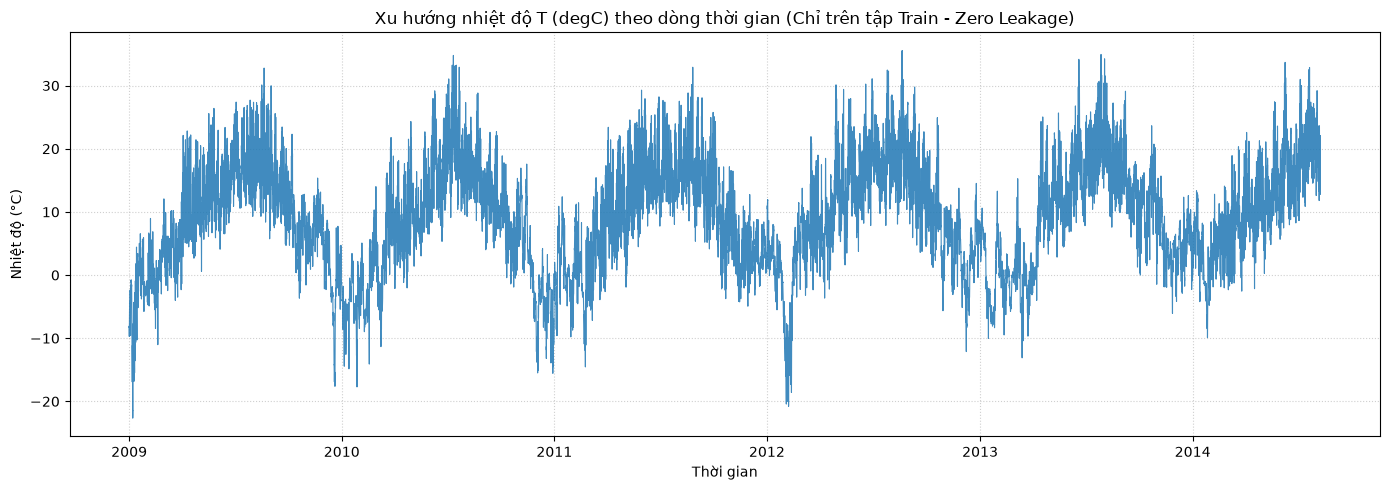

In [4]:
# 1. Xu hướng biến thiên nhiệt độ theo dòng thời gian (Chỉ trên 70% tập Train)
plot_temperature_trend(train_df)

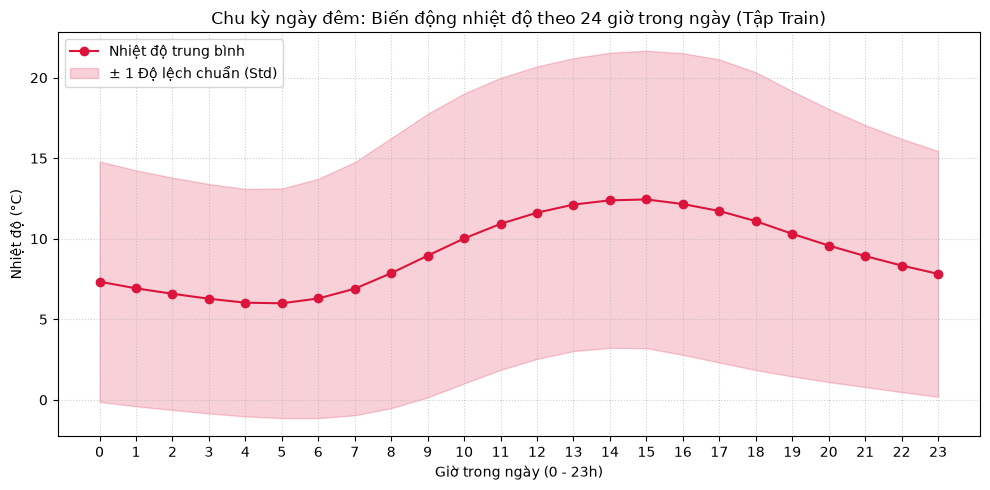

In [5]:
# 2. Chu kỳ dao động nhiệt độ ngày đêm theo 24 giờ (Chỉ trên 70% tập Train)
plot_diurnal_cycle(train_df)

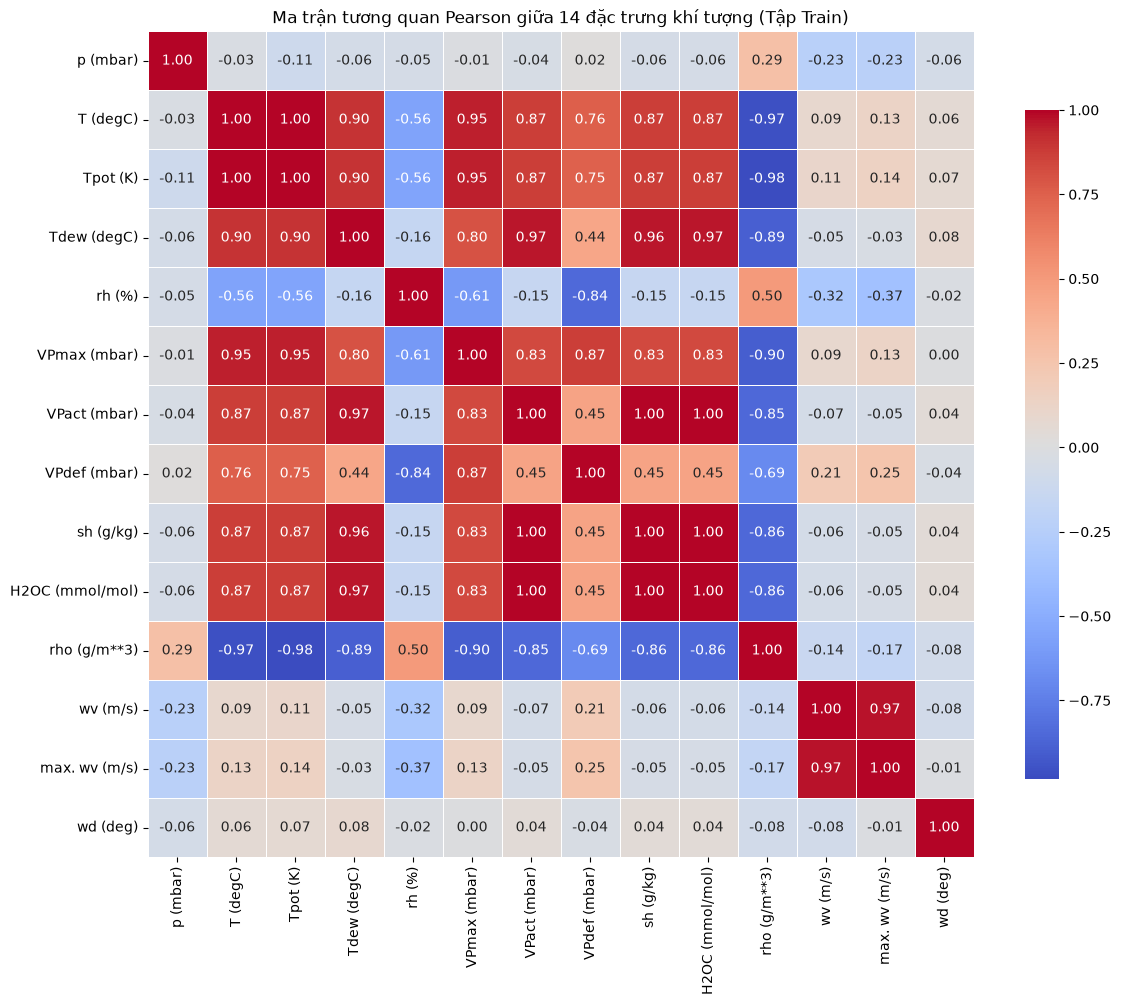

In [6]:
# 3. Ma trận tương quan Pearson giữa 14 đặc trưng khí tượng (Chỉ trên 70% tập Train)
plot_correlation_heatmap(train_df)

### 4. Kiểm Thử Không Rò Rỉ Dữ Liệu (Zero Leakage Check)

In [7]:
dm.fit_scaler_and_impute()
assert dm.verify_zero_leakage() is True
print("Hoàn tất kiểm định: Tập Train, Val, Test hoàn toàn độc lập và không rò rỉ dữ liệu!")

Hoàn tất kiểm định: Tập Train, Val, Test hoàn toàn độc lập và không rò rỉ dữ liệu!
